# Twitter-XLM-RoBERTa-base: E2: warmup, learning rate, dan label smoothing

## 1. Library dan konfigurasi

In [1]:
import os

# Tetapkan backend sebelum datasets dan transformers diimpor.
os.environ["USE_TF"] = "0"
os.environ["USE_TORCH"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import sys
import re
import gc
import json
import hashlib
import shutil
import unicodedata
import io
from zipfile import ZipFile, ZIP_DEFLATED
from pathlib import Path
from itertools import combinations
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, FileLink
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    EarlyStoppingCallback, Trainer, TrainingArguments, set_seed,
)

# Semua skenario memakai E2: komentar raw dan weighted cross-entropy.
LANGUAGES = ["en", "it", "nl"]
MODEL_NAMES = ["cardiffnlp/twitter-xlm-roberta-base"]
# Untuk satu bahasa saja: LANGUAGES = ["en"]
# Semua model: MODEL_NAMES = ["cardiffnlp/twitter-xlm-roberta-base", "FacebookAI/xlm-roberta-base",
#                             "google-bert/bert-base-multilingual-uncased"]

RUN_NAMES = ["E2_baseline", "E2_warmup", "E2_learning_rate", "E2_label_smoothing"]

SEED = 42
MAX_LENGTH = 384  # Sama dengan notebook lama
NUM_EPOCHS = 10
PATIENCE = 3
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 16
GRADIENT_CHECKPOINTING = True
EVAL_ACCUMULATION_STEPS = 1
WEIGHT_DECAY = 0.01
USE_DRIVE = False  # True: mount Drive untuk menyimpan hasil permanen
SKIP_FINISHED = True  # Aman melanjutkan setelah runtime terputus
RUN_FINAL_TEST = False  # Aktifkan setelah konfigurasi final dipilih dari validation.

IN_COLAB = "google.colab" in sys.modules
candidates = [Path.cwd() / "data", Path.cwd().parent / "data", Path.cwd() / "Analisis" / "data"]
DATA_DIR = next(
    (path for path in candidates if any((path / f"{lang}-splitting").is_dir() for lang in LANGUAGES)),
    Path("/content/data") if IN_COLAB else Path.cwd() / "data",
).resolve()
if USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/StereoQueerEval_E2_Tuning")
else:
    OUT_DIR = (
        Path("/content/e2_tuning_results")
        if IN_COLAB
        else DATA_DIR.parent / "results" / "e2_tuning_multibahasa"
    ).resolve()
OUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODELS_FILE = OUT_DIR.parent / "best_models.json"
best_models = json.loads(BEST_MODELS_FILE.read_text(encoding="utf-8")) if BEST_MODELS_FILE.exists() else {}

LABELS = ["no", "yes_implicit", "yes_explicit"]
LABEL2ID = {label: idx for idx, label in enumerate(LABELS)}
ID2LABEL = {idx: label for label, idx in LABEL2ID.items()}
assert set(LANGUAGES).issubset({"en", "it", "nl"}) and LANGUAGES
assert MODEL_NAMES
print("Eksperimen:", RUN_NAMES)
print("Bahasa:", LANGUAGES)
print("Model:", MODEL_NAMES)
print("Total pelatihan:", len(LANGUAGES) * len(MODEL_NAMES) * len(RUN_NAMES))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "TIDAK TERDETEKSI")
print("Folder hasil:", OUT_DIR)


def cleanup():
    """Lepaskan objek tidak terpakai dan cache GPU antar-run."""
    plt.close("all")
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


c:\Users\solon\AppData\Local\Programs\Python\Python312\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.0.1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Eksperimen: ['E2_baseline', 'E2_warmup', 'E2_learning_rate', 'E2_label_smoothing']
Bahasa: ['en', 'it', 'nl']
Model: ['cardiffnlp/twitter-xlm-roberta-base']
Total pelatihan: 12
GPU: NVIDIA GeForce RTX 3060 Ti
Folder hasil: E:\Projek\PTM\TBP\Analisis\results\e2_tuning_multibahasa


## 2. Lokasi data dan upload opsional

In [2]:
DATA_DIR.mkdir(parents=True, exist_ok=True)


def data_path(lang, split):
    name = f"{lang}-{split}.csv"
    nested = DATA_DIR / f"{lang}-splitting" / name
    return nested if nested.is_file() else DATA_DIR / name


needed_names = [f"{lang}-{split}.csv" for lang in LANGUAGES for split in ("train", "val", "test")]
missing = [
    f"{lang}-{split}.csv"
    for lang in LANGUAGES
    for split in ("train", "val", "test")
    if not data_path(lang, split).is_file()
]
if missing:
    if not IN_COLAB:
        raise FileNotFoundError(f"CSV belum ditemukan di {DATA_DIR}: {missing}")
    from google.colab import files

    print("Unggah CSV atau ZIP untuk bahasa terpilih:", missing)
    uploaded = files.upload()
    for filename, blob in uploaded.items():
        if filename.lower().endswith(".zip"):
            with ZipFile(io.BytesIO(blob)) as z:
                for entry in z.infolist():
                    base = Path(entry.filename).name
                    if not entry.is_dir() and base in needed_names:
                        (DATA_DIR / base).write_bytes(z.read(entry))
        elif filename in needed_names:
            (DATA_DIR / filename).write_bytes(blob)
    if uploaded:
        del blob
    del uploaded
    cleanup()
missing = [
    str(data_path(lang, split))
    for lang in LANGUAGES
    for split in ("train", "val", "test")
    if not data_path(lang, split).is_file()
]
if missing:
    raise FileNotFoundError("CSV belum lengkap: " + ", ".join(missing))
print("Semua split bahasa terpilih tersedia. Tidak ada splitting ulang.")


Semua split bahasa terpilih tersedia. Tidak ada splitting ulang.


## 3. Baca data dan periksa overlap

In [3]:
DATA = {}
for lang in LANGUAGES:
    frames = {}
    for split in ("train", "val", "test"):
        path = data_path(lang, split)
        frame = pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")
        required = {"StereoQueerEval_id", "yt_comment", "hate_speech"}
        assert required <= set(frame.columns), f"Kolom tidak lengkap: {path}"
        assert not frame.empty and frame["StereoQueerEval_id"].is_unique
        assert frame["StereoQueerEval_id"].str.strip().ne("").all()
        assert frame["yt_comment"].str.strip().ne("").all()
        assert set(frame["hate_speech"]) == set(LABELS)
        frames[split] = frame

    for left, right in combinations(frames, 2):
        for column in ("StereoQueerEval_id", "yt_comment"):
            left_values = frames[left][column].map(
                lambda text: re.sub(r"\s+", " ", unicodedata.normalize("NFKC", text).casefold()).strip()
            )
            right_values = frames[right][column].map(
                lambda text: re.sub(r"\s+", " ", unicodedata.normalize("NFKC", text).casefold()).strip()
            )
            assert not set(left_values) & set(right_values), f"Overlap {column}: {lang} {left}/{right}"
    DATA[lang] = frames
    print(lang.upper(), {split: len(frame) for split, frame in frames.items()})


EN {'train': 2111, 'val': 292, 'test': 586}
IT {'train': 1699, 'val': 220, 'test': 481}
NL {'train': 1556, 'val': 226, 'test': 456}


## 4. Konfigurasi eksperimen E2

In [4]:
# Satu perubahan per skenario terhadap E2_baseline.
EXPERIMENTS = {
    "E2_baseline":        {"lr": 1e-5, "warmup": 0.0, "label_smoothing": 0.0},
    "E2_warmup":          {"lr": 1e-5, "warmup": 0.1, "label_smoothing": 0.0},
    "E2_learning_rate":   {"lr": 2e-5, "warmup": 0.0, "label_smoothing": 0.0},
    "E2_label_smoothing": {"lr": 1e-5, "warmup": 0.0, "label_smoothing": 0.05},
}
assert all(name in EXPERIMENTS for name in RUN_NAMES)


## 5. Metrik, tokenisasi, dan penyimpanan JSON

In [5]:
def compute_metrics(prediction):
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    y_true = prediction.label_ids
    y_pred = np.asarray(logits).argmax(axis=-1)
    report = classification_report(
        y_true, y_pred, labels=[0, 1, 2], target_names=LABELS, output_dict=True, zero_division=0
    )
    scores = {
        "macro_f1": float(f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "weighted_f1": float(f1_score(y_true, y_pred, labels=[0, 1, 2], average="weighted", zero_division=0)),
    }
    for label in LABELS:
        for metric in ("f1-score", "recall", "precision"):
            name = "f1" if metric == "f1-score" else metric
            scores[f"{name}_{label}"] = float(report[label][metric])
    return scores


def tokenize_split(frame, tokenizer):
    # E2 mempertahankan kapitalisasi, emoji, dan isi komentar asli.
    tokens = tokenizer(frame["yt_comment"].tolist(), max_length=MAX_LENGTH, truncation=True)
    tokens["labels"] = frame["hate_speech"].map(LABEL2ID).tolist()
    return Dataset.from_dict(tokens)


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    value = json.loads(json.dumps(value, ensure_ascii=False), parse_constant=str)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")


def compute_loss(outputs, labels, num_items_in_batch=None, class_weights=None, label_smoothing=0.0):
    weights = class_weights.to(outputs.logits.device) if class_weights is not None else None
    return torch.nn.functional.cross_entropy(
        outputs.logits.float(), labels, weight=weights, label_smoothing=label_smoothing,
    )


## 6. Training dan evaluasi validation

In [6]:
if not torch.cuda.is_available():
    raise RuntimeError("GPU CUDA tidak tersedia.")

records = []
for lang in LANGUAGES:
    for model_name in MODEL_NAMES:
        for run_name in RUN_NAMES:
            print(f"\n{lang.upper()} | {model_name} | {run_name}")
            conf = EXPERIMENTS[run_name]
            directory = OUT_DIR / lang / model_name.split("/")[-1] / run_name
            metrics_file = directory / "validation_metrics.json"
            run_config = {
                "model": model_name, "language": lang, "scenario": conf,
                "input": "yt_comment", "preprocessing": "raw", "weighted": True,
                "seed": SEED, "max_length": MAX_LENGTH, "epochs": NUM_EPOCHS, "patience": PATIENCE,
                "train_batch_size": TRAIN_BATCH_SIZE, "eval_batch_size": EVAL_BATCH_SIZE,
                "weight_decay": WEIGHT_DECAY, "gradient_checkpointing": GRADIENT_CHECKPOINTING,
                "eval_accumulation_steps": EVAL_ACCUMULATION_STEPS,
                "data_sha256": {
                    split: hashlib.sha256(data_path(lang, split).read_bytes()).hexdigest()
                    for split in ("train", "val", "test")
                },
            }
            if SKIP_FINISHED and metrics_file.exists():
                saved_config = json.loads((directory / "configuration.json").read_text(encoding="utf-8"))
                if saved_config != run_config:
                    raise ValueError(f"Konfigurasi berubah. Gunakan folder hasil baru: {directory}")
                print(f"Melewati {lang}/{model_name}/{run_name}: sudah selesai sebelumnya")
                records.append(json.loads(metrics_file.read_text(encoding="utf-8")))
                continue
            directory.mkdir(parents=True, exist_ok=True)
            set_seed(SEED)
            cleanup()
            trainer = model = train_ds = val_ds = tokenizer = None
            pred = logits = y_true = y_pred = validation_pred = None
            try:
                tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
                train_ds = tokenize_split(DATA[lang]["train"], tokenizer)
                val_ds = tokenize_split(DATA[lang]["val"], tokenizer)
                class_counts = (
                    DATA[lang]["train"]["hate_speech"]
                    .map(LABEL2ID)
                    .value_counts()
                    .reindex(range(3))
                    .to_numpy()
                )
                class_weights = torch.tensor(
                    len(DATA[lang]["train"]) / (3 * class_counts), dtype=torch.float32
                )

                model = AutoModelForSequenceClassification.from_pretrained(
                    model_name, num_labels=3, label2id=LABEL2ID, id2label=ID2LABEL
                )
                model.config.use_cache = False
                args = TrainingArguments(
                    output_dir=str(directory / "checkpoints"), eval_strategy="epoch",
                    save_strategy="best", logging_strategy="epoch",
                    learning_rate=conf["lr"], warmup_ratio=conf["warmup"],
                    weight_decay=WEIGHT_DECAY, num_train_epochs=NUM_EPOCHS,
                    per_device_train_batch_size=TRAIN_BATCH_SIZE, per_device_eval_batch_size=EVAL_BATCH_SIZE,
                    gradient_accumulation_steps=1, seed=SEED,
                    data_seed=SEED, gradient_checkpointing=GRADIENT_CHECKPOINTING,
                    eval_accumulation_steps=EVAL_ACCUMULATION_STEPS, fp16=torch.cuda.is_available(),
                    bf16=False, load_best_model_at_end=True,
                    metric_for_best_model="macro_f1", greater_is_better=True,
                    save_total_limit=1, save_safetensors=True, save_only_model=True,
                    report_to="none", dataloader_num_workers=0,
                    optim="adamw_torch", lr_scheduler_type="linear",
                )
                trainer = Trainer(
                    model=model, args=args,
                    train_dataset=train_ds, eval_dataset=val_ds,
                    processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
                    compute_metrics=compute_metrics,
                    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
                    compute_loss_func=partial(
                        compute_loss, class_weights=class_weights, label_smoothing=conf["label_smoothing"],
                    ),
                )
                trainer.model_accepts_loss_kwargs = False
                trainer.train()
                pred = trainer.predict(val_ds)
                logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
                y_true = pred.label_ids
                y_pred = np.argmax(logits, axis=-1)
                metrics = compute_metrics(pred)
                metrics.update(
                    {
                        "language": lang,
                        "model": model_name,
                        "run_name": run_name,
                        "best_checkpoint": str(trainer.state.best_model_checkpoint),
                        "seed": SEED,
                        "data_sha256": hashlib.sha256(data_path(lang, "train").read_bytes()).hexdigest(),
                    }
                )
                save_json(directory / "configuration.json", run_config)
                save_json(directory / "training_arguments.json", args.to_dict())
                pd.DataFrame(trainer.state.log_history).to_csv(
                    directory / "training_history.csv", index=False
                )
                pd.DataFrame(
                    classification_report(
                        y_true,
                        y_pred,
                        labels=[0, 1, 2], target_names=LABELS,
                        output_dict=True, zero_division=0,
                    )
                ).transpose().to_csv(directory / "classification_report_validation.csv")
                pd.DataFrame(
                    confusion_matrix(y_true, y_pred, labels=[0, 1, 2]), index=LABELS, columns=LABELS
                ).to_csv(directory / "confusion_matrix_validation.csv", index_label="actual_label")
                validation_pred = DATA[lang]["val"][
                    ["StereoQueerEval_id", "yt_comment", "hate_speech"]
                ].copy()
                validation_pred["predicted_label"] = [ID2LABEL[int(v)] for v in y_pred]
                validation_pred["correct"] = (
                    validation_pred["hate_speech"] == validation_pred["predicted_label"]
                )
                validation_pred.to_csv(directory / "predictions_validation.csv", index=False)
                # Tandai lengkap PALING AKHIR agar kegagalan menyimpan tidak dianggap selesai.
                save_json(metrics_file, metrics)
                # Simpan satu pemenang untuk setiap pasangan model dan bahasa.
                model_key = model_name.split("/")[-1] + "/" + lang
                previous = best_models.get(model_key)
                if previous is None or metrics["macro_f1"] > previous["score"]:
                    best_models[model_key] = {
                        "model": model_name.split("/")[-1], "language": lang,
                        "score": metrics["macro_f1"], "path": metrics["best_checkpoint"],
                        "run": str(directory.resolve()),
                    }
                    save_json(BEST_MODELS_FILE, best_models)

                winner_path = Path(best_models[model_key]["path"]).resolve()
                obsolete = list((directory / "checkpoints").glob("checkpoint-*"))
                if previous is not None:
                    obsolete.append(Path(previous["path"]))
                for checkpoint in obsolete:
                    checkpoint = checkpoint.resolve()
                    if checkpoint != winner_path and checkpoint.exists():
                        assert checkpoint.is_relative_to(OUT_DIR.parent.resolve())
                        assert checkpoint.name.startswith("checkpoint-") or checkpoint.name == "best_model"
                        shutil.rmtree(checkpoint)
                records.append(metrics)
                comparison = pd.DataFrame(records)
                comparison.to_csv(OUT_DIR / "SEMUA_HASIL_VALIDASI.csv", index=False)
                print(f"Validation macro-F1: {metrics['macro_f1']:.4f}")
            finally:
                # Lepaskan referensi sebelum membersihkan cache GPU.
                del trainer, model, train_ds, val_ds, tokenizer
                del pred, logits, y_true, y_pred, validation_pred
                cleanup()



EN | cardiffnlp/twitter-xlm-roberta-base | E2_baseline


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at cardiffnlp/twitter-xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy,Weighted F1,F1 No,Recall No,Precision No,F1 Yes Implicit,Recall Yes Implicit,Precision Yes Implicit,F1 Yes Explicit,Recall Yes Explicit,Precision Yes Explicit
1,1.095000,1.070750,0.459098,0.458904,0.451384,0.428571,0.285714,0.857143,0.470000,0.671429,0.361538,0.478723,0.600000,0.398230
2,0.998800,0.957201,0.573255,0.630137,0.614186,0.732733,0.829932,0.655914,0.479339,0.414286,0.568627,0.507692,0.440000,0.600000
3,0.909500,0.925048,0.591575,0.633562,0.632677,0.751678,0.761905,0.741722,0.496732,0.542857,0.457831,0.526316,0.466667,0.603448
4,0.817100,0.944239,0.564436,0.585616,0.598625,0.697318,0.619048,0.798246,0.481283,0.642857,0.384615,0.514706,0.466667,0.573770
5,0.732900,0.944790,0.604220,0.633562,0.638726,0.737589,0.707483,0.770370,0.509554,0.571429,0.459770,0.565517,0.546667,0.585714
6,0.649800,0.978211,0.595985,0.633562,0.634477,0.746575,0.741497,0.751724,0.516556,0.557143,0.481481,0.524823,0.493333,0.560606
7,0.578100,1.008102,0.588233,0.619863,0.626701,0.739130,0.693878,0.790698,0.514620,0.628571,0.435644,0.510949,0.466667,0.564516
8,0.536800,1.036961,0.613243,0.647260,0.650176,0.756944,0.741497,0.773050,0.525641,0.585714,0.476744,0.557143,0.520000,0.600000
9,0.491300,1.059034,0.620924,0.660959,0.660886,0.778157,0.775510,0.780822,0.551282,0.614286,0.500000,0.533333,0.480000,0.600000
10,0.471500,1.078868,0.607960,0.647260,0.647918,0.765517,0.755102,0.776224,0.543210,0.628571,0.478261,0.515152,0.453333,0.596491


Validation macro-F1: 0.6080

EN | cardiffnlp/twitter-xlm-roberta-base | E2_warmup


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at cardiffnlp/twitter-xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


...

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy,Weighted F1,F1 No,Recall No,Precision No,F1 Yes Implicit,Recall Yes Implicit,Precision Yes Implicit,F1 Yes Explicit,Recall Yes Explicit,Precision Yes Explicit
1,1.091700,1.064578,0.469536,0.544248,0.514283,0.686441,0.743119,0.637795,0.481203,0.581818,0.410256,0.240964,0.161290,0.476190
2,0.966200,0.956855,0.528518,0.553097,0.560199,0.669951,0.623853,0.723404,0.455285,0.509091,0.411765,0.460317,0.467742,0.453125
3,0.835100,1.051271,0.506943,0.557522,0.550873,0.691244,0.688073,0.694444,0.326087,0.272727,0.405405,0.503497,0.580645,0.444444
4,0.721700,1.060026,0.513772,0.544248,0.550528,0.673077,0.642202,0.707071,0.396694,0.436364,0.363636,0.471545,0.467742,0.475410
5,0.614600,1.193801,0.484407,0.535398,0.533313,0.699552,0.715596,0.684211,0.350000,0.381818,0.323077,0.403670,0.354839,0.468085


Validation macro-F1: 0.4844

NL | cardiffnlp/twitter-xlm-roberta-base | E2_label_smoothing


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at cardiffnlp/twitter-xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy,Weighted F1,F1 No,Recall No,Precision No,F1 Yes Implicit,Recall Yes Implicit,Precision Yes Implicit,F1 Yes Explicit,Recall Yes Explicit,Precision Yes Explicit
1,1.108300,1.092662,0.435292,0.460177,0.462345,0.567901,0.422018,0.867925,0.452261,0.818182,0.312500,0.285714,0.209677,0.448276
2,1.041100,0.987395,0.522281,0.544248,0.556410,0.666667,0.577982,0.787500,0.389831,0.418182,0.365079,0.510345,0.596774,0.445783
3,0.950300,1.022068,0.511861,0.570796,0.557845,0.701422,0.678899,0.725490,0.300000,0.218182,0.480000,0.534161,0.693548,0.434343
4,0.896600,0.984450,0.527473,0.544248,0.556212,0.648649,0.550459,0.789474,0.413223,0.454545,0.378788,0.520548,0.612903,0.452381
5,0.853900,1.003430,0.508132,0.544248,0.545598,0.659794,0.587156,0.752941,0.316832,0.290909,0.347826,0.547771,0.693548,0.452632
6,0.815000,1.029388,0.533630,0.575221,0.576900,0.717703,0.688073,0.750000,0.372549,0.345455,0.404255,0.510638,0.580645,0.455696
7,0.775100,1.083672,0.539083,0.584071,0.581465,0.723214,0.743119,0.704348,0.407080,0.418182,0.396552,0.486957,0.451613,0.528302
8,0.750700,1.099376,0.521643,0.570796,0.565886,0.716814,0.743119,0.692308,0.403670,0.400000,0.407407,0.444444,0.419355,0.472727
9,0.718800,1.099469,0.526777,0.570796,0.568944,0.711712,0.724771,0.699115,0.407080,0.418182,0.396552,0.461538,0.435484,0.490909
10,0.700900,1.084235,0.509924,0.553097,0.555328,0.704225,0.688073,0.721154,0.348624,0.345455,0.351852,0.476923,0.500000,0.455882


Validation macro-F1: 0.5099


## 7. Perbandingan hasil validation

,language,model,run_name,macro_f1,delta_macro_f1,accuracy,f1_no,f1_yes_implicit,f1_yes_explicit
0,en,cardiffnlp/twitter-xlm-roberta-base,E2_warmup,0.6085,0.0005,0.6473,0.7593,0.5298,0.5362
1,en,cardiffnlp/twitter-xlm-roberta-base,E2_baseline,0.6080,0.0000,0.6473,0.7655,0.5432,0.5152
2,en,cardiffnlp/twitter-xlm-roberta-base,E2_label_smoothing,0.6054,-0.0025,0.6438,0.7612,0.5399,0.5152
3,en,cardiffnlp/twitter-xlm-roberta-base,E2_learning_rate,0.5665,-0.0414,0.6096,0.7552,0.4561,0.4882
4,it,cardiffnlp/twitter-xlm-roberta-base,E2_baseline,0.5623,0.0000,0.6045,0.7273,0.3838,0.5758
5,it,cardiffnlp/twitter-xlm-roberta-base,E2_label_smoothing,0.5544,-0.0079,0.5955,0.7177,0.3762,0.5692
6,it,cardiffnlp/twitter-xlm-roberta-base,E2_warmup,0.5526,-0.0097,0.5955,0.7238,0.3800,0.5538
7,it,cardiffnlp/twitter-xlm-roberta-base,E2_learning_rate,0.5051,-0.0572,0.5273,0.6597,0.3939,0.4615
8,nl,cardiffnlp/twitter-xlm-roberta-base,E2_baseline,0.5176,0.0000,0.5354,0.6486,0.3902,0.5139
9,nl,cardiffnlp/twitter-xlm-roberta-base,E2_warmup,0.5173,-0.0003,0.5619,0.7000,0.3519,0.5000


PEMENANG VALIDASI UNTUK SETIAP PASANG MODEL/BAHASA:


,language,model,run_name,macro_f1,delta_macro_f1,accuracy,f1_no,f1_yes_implicit,f1_yes_explicit
0,en,cardiffnlp/twitter-xlm-roberta-base,E2_warmup,0.608452,0.000492,0.647260,0.759322,0.529801,0.536232
4,it,cardiffnlp/twitter-xlm-roberta-base,E2_baseline,0.562290,0.000000,0.604545,0.727273,0.383838,0.575758
8,nl,cardiffnlp/twitter-xlm-roberta-base,E2_baseline,0.517594,0.000000,0.535398,0.648649,0.390244,0.513889


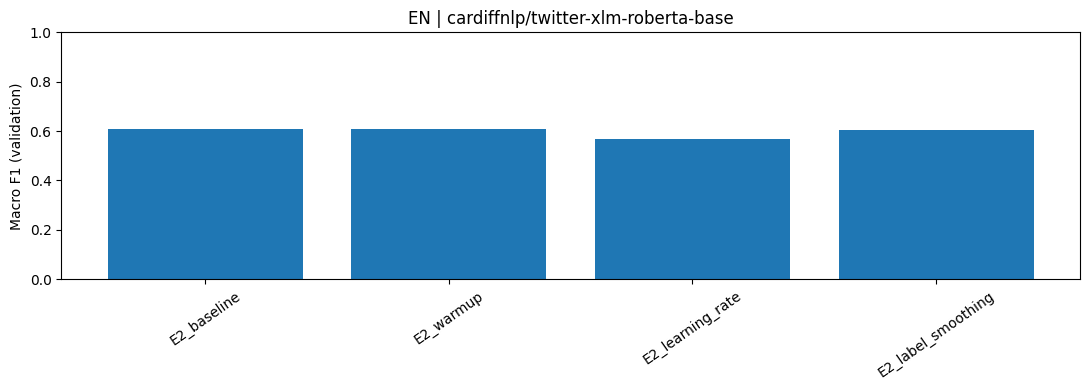

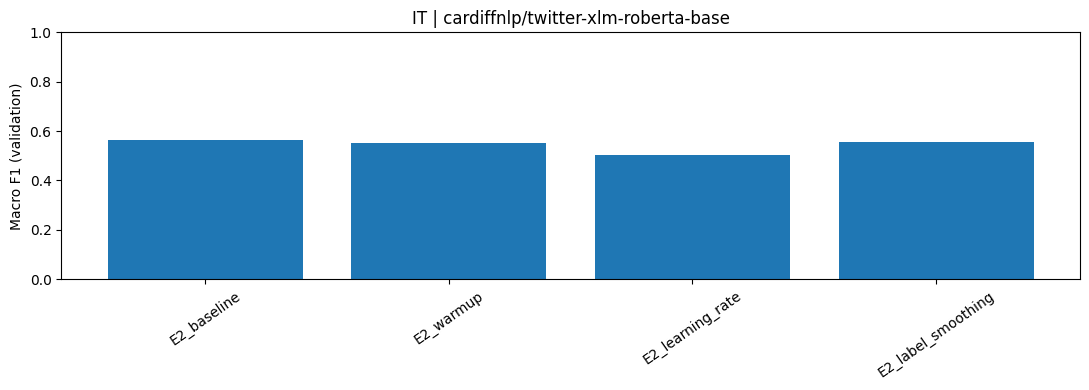

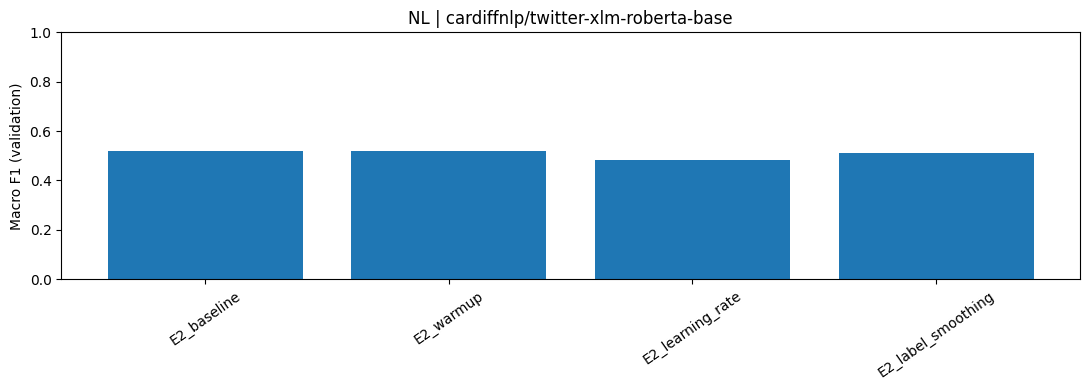

Model yang dipertahankan tercatat di: E:\Projek\PTM\TBP\Analisis\results\best_models.json
Checkpoint eksperimen kalah sudah dibersihkan setelah masing-masing run.


In [7]:
records = []
for lang in LANGUAGES:
    for model_name in MODEL_NAMES:
        for run_name in RUN_NAMES:
            path = OUT_DIR / lang / model_name.split("/")[-1] / run_name / "validation_metrics.json"
            if path.exists():
                records.append(json.loads(path.read_text(encoding="utf-8")))
comparison = pd.DataFrame(records)
if comparison.empty:
    raise RuntimeError("Belum ada hasil validation.")
comparison = comparison.sort_values(["language", "model", "macro_f1"], ascending=[True, True, False])
baseline = comparison[comparison["run_name"] == "E2_baseline"][["language", "model", "macro_f1"]]
comparison = comparison.merge(
    baseline.rename(columns={"macro_f1": "baseline_macro_f1"}), on=["language", "model"], how="left",
)
comparison["delta_macro_f1"] = comparison["macro_f1"] - comparison["baseline_macro_f1"]
comparison.to_csv(OUT_DIR / "SEMUA_HASIL_VALIDASI.csv", index=False)
cols = [
    "language",
    "model",
    "run_name",
    "macro_f1",
    "delta_macro_f1",
    "accuracy",
    "f1_no",
    "f1_yes_implicit",
    "f1_yes_explicit",
]
display(
    comparison[cols].style.format({x: "{:.4f}" for x in cols if x not in ("language", "model", "run_name")})
)

winners = comparison.sort_values("macro_f1", ascending=False).drop_duplicates(["language", "model"])
print("PEMENANG VALIDASI UNTUK SETIAP PASANG MODEL/BAHASA:")
display(winners[cols])
for (lang, model_name), group in comparison.groupby(["language", "model"], sort=False):
    order = [x for x in RUN_NAMES if x in set(group["run_name"])]
    group = group.set_index("run_name").loc[order]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(group.index, group["macro_f1"])
    ax.set_ylim(0, 1)
    ax.set(ylabel="Macro F1 (validation)", title=f"{lang.upper()} | {model_name}")
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    out = OUT_DIR / lang / model_name.split("/")[-1] / "comparison_macro_f1.png"
    out.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out, dpi=160)
    plt.show()
    plt.close(fig)

print("Model yang dipertahankan tercatat di:", BEST_MODELS_FILE)
print("Checkpoint eksperimen kalah sudah dibersihkan setelah masing-masing run.")


## 8. Evaluasi test konfigurasi terpilih

In [8]:
if not RUN_FINAL_TEST:
    print("Evaluasi test dikunci. Tinjau hasil validasi dahulu; ubah RUN_FINAL_TEST=True setelah final.")
else:
    assert not comparison.empty, "Hasil validasi belum tersedia"
    # Jika memilih lintas model, pastikan FINAL_MODEL dan FINAL_RUN ditetapkan berdasarkan validasi saja.
    for FINAL_LANGUAGE in LANGUAGES:
        for FINAL_MODEL in MODEL_NAMES:
            final_pool = comparison[
                (comparison["language"] == FINAL_LANGUAGE) & (comparison["model"] == FINAL_MODEL)
            ]
            assert len(final_pool) == len(RUN_NAMES), "Selesaikan seluruh eksperimen sebelum tes."
            FINAL_RUN = final_pool.sort_values("macro_f1", ascending=False).iloc[0]["run_name"]
            print("Final (berdasarkan validasi):", FINAL_LANGUAGE, FINAL_MODEL, FINAL_RUN)
            destination = OUT_DIR / FINAL_LANGUAGE / FINAL_MODEL.split("/")[-1] / FINAL_RUN
            target = destination / "test_metrics.json"
            if target.exists():
                print("Hasil test sudah ada, tidak dihitung ulang:")
                print(target.read_text(encoding="utf-8"))
            else:
                checkpoint = final_pool[final_pool["run_name"] == FINAL_RUN].iloc[0]["best_checkpoint"]
                if not Path(checkpoint).exists():
                    kept = best_models.get(FINAL_MODEL.split("/")[-1] + "/" + FINAL_LANGUAGE)
                    if kept and Path(kept["path"]).exists():
                        print("Pemenang tersimpan berasal dari run lain:", kept["path"])
                        print("Gunakan notebook dan preprocessing run tersebut untuk evaluasi test.")
                        continue
                    raise FileNotFoundError(f"Checkpoint tidak ditemukan: {checkpoint}")
                cleanup()
                trainer = model = test_ds = tokenizer = pred = logits = y_true = y_pred = None
                try:
                    tokenizer = AutoTokenizer.from_pretrained(FINAL_MODEL, use_fast=True)
                    model = AutoModelForSequenceClassification.from_pretrained(checkpoint)
                    test_ds = tokenize_split(DATA[FINAL_LANGUAGE]["test"], tokenizer)
                    args = TrainingArguments(
                        output_dir=str(destination / "test_only"), per_device_eval_batch_size=EVAL_BATCH_SIZE,
                        eval_accumulation_steps=EVAL_ACCUMULATION_STEPS, report_to="none",
                    )
                    trainer = Trainer(
                        model=model, args=args,
                        processing_class=tokenizer,
                        data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
                        compute_metrics=compute_metrics,
                    )
                    pred = trainer.predict(test_ds)
                    logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
                    y_true = pred.label_ids
                    y_pred = np.asarray(logits).argmax(axis=-1)
                    final_scores = compute_metrics(pred)
                    pd.DataFrame(
                        confusion_matrix(y_true, y_pred, labels=[0, 1, 2]), index=LABELS, columns=LABELS
                    ).to_csv(destination / "confusion_matrix_test.csv", index_label="actual_label")
                    pd.DataFrame(
                        classification_report(
                            y_true,
                            y_pred,
                            labels=[0, 1, 2], target_names=LABELS,
                            output_dict=True, zero_division=0,
                        )
                    ).transpose().to_csv(destination / "classification_report_test.csv")
                    save_json(
                        target,
                        {
                            "language": FINAL_LANGUAGE,
                            "model": FINAL_MODEL,
                            "run_name": FINAL_RUN,
                            "scores": final_scores,
                        },
                    )
                    print("TEST INTERNAL (bukan official test SemEval):")
                    display(pd.DataFrame([final_scores]))
                    print(
                        classification_report(
                            y_true, y_pred, labels=[0, 1, 2], target_names=LABELS, zero_division=0
                        )
                    )
                finally:
                    del trainer, model, test_ds, tokenizer, pred, logits, y_true, y_pred
                    cleanup()


Evaluasi test dikunci. Tinjau hasil validasi dahulu; ubah RUN_FINAL_TEST=True setelah final.


## 9. Ekspor laporan ZIP

In [9]:
if comparison.empty:
    print("Belum ada hasil eksperimen yang dapat diekspor.")
else:
    archive_base = OUT_DIR / "laporan_e2_tuning"
    with ZipFile(str(archive_base) + ".zip", "w", compression=ZIP_DEFLATED) as archive:
        for file in OUT_DIR.rglob("*"):
            if (
                file.is_file()
                and "checkpoints" not in file.parts
                and file.suffix.lower() != ".zip"
            ):
                archive.write(file, arcname=file.relative_to(OUT_DIR))
    print("CSV:", OUT_DIR / "SEMUA_HASIL_VALIDASI.csv")
    print("ZIP:", str(archive_base) + ".zip")
    display(FileLink(str(archive_base) + ".zip"))
    print("Catatan: kirim CSV hasil ke chat agar saya bedah perbedaan keempat eksperimen E2.")


CSV: E:\Projek\PTM\TBP\Analisis\results\e2_tuning_multibahasa\SEMUA_HASIL_VALIDASI.csv
ZIP: E:\Projek\PTM\TBP\Analisis\results\e2_tuning_multibahasa\laporan_e2_tuning.zip


E:\Projek\PTM\TBP\Analisis\results\e2_tuning_multibahasa\laporan_e2_tuning.zip

Catatan: kirim CSV hasil ke chat agar saya bedah perbedaan keempat eksperimen E2.
